# 03 Second optimization round
Prerequisite: finish notebooks 01 and 02 using the same RUN_NAME.
Inherit the first-round winners, tune RF/XGBoost sampling and carry forward LR unchanged.


In [1]:
# If the kernel is missing dependencies, uncomment the next line, execute it,
# then restart the kernel before continuing. This notebook never auto-installs packages.
# %pip install -r requirements-notebooks.txt


In [2]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import cross_validate, GridSearchCV

# Set this only when Jupyter is launched outside the project.
PROJECT_ROOT = None  # Example: Path(r"/path/to/final project")
if PROJECT_ROOT is None:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / "data/processed/caroline_cleaned version/cardio_train_80.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the project folder containing data/ and notebooks/.")
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks/model_training_jupyter"
sys.path.insert(0, str(NOTEBOOK_DIR))
from training_utils import (
    FEATURES, METRICS, SEED, MODEL_NAMES, load_development, build_pipeline,
    scorers, select_auc, begin_stage, collect_cv, save_model_result,
    finish_stage, load_stage, comparison_plots, compare_history,
)

# Use the SAME name in all three notebooks. Use a new name for a fresh rerun.
RUN_NAME = "seven_features_run_01"
RUN_DIR = NOTEBOOK_DIR / "runs" / RUN_NAME
print("Project:", PROJECT_ROOT)
print("Run output:", RUN_DIR)
print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgboost.__version__)


Project: /Users/liujueshan/Desktop/comp4145/final project
Run output: /Users/liujueshan/Desktop/comp4145/final project/notebooks/model_training_jupyter/runs/seven_features_run_01
scikit-learn: 1.9.1 | XGBoost: 3.4.1


Seven inputs: age, gender, BMI, systolic BP, diastolic BP, cholesterol and glucose.
Categorical encoding produces nine model columns. Logistic regression scales numeric inputs
inside each training fold; tree models do not scale them. The five grouped folds are identical
across models and stages. All classification metrics use `score >= 0.5`.

Tables report **five-fold validation means**. ROC/confusion plots use pooled out-of-fold (OOF)
predictions, so pooled AUC may differ slightly from the mean fold AUC.


In [3]:
# No test CSV is loaded. Continuous inputs are restored to original units.
ctx = load_development(PROJECT_ROOT)
X, y, cv = ctx["X"], ctx["y"], ctx["cv"]
assert X.shape == (54855, 7)
assert "cardio" not in FEATURES and "id" not in FEATURES
print("Input features:", FEATURES)
display(pd.DataFrame(X, columns=FEATURES).head())
display(pd.Series(y, name="cardio").value_counts().rename_axis("label").to_frame("records"))
display(pd.DataFrame([
    {"fold": i, "training_records": len(train), "validation_records": len(valid)}
    for i, (train, valid) in enumerate(cv, 1)
]))


Input features: ['age_years', 'gender', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc']


,age_years,gender,bmi,ap_hi,ap_lo,cholesterol,gluc
0,59.890486,2.0,25.306932,120.0,80.0,1.0,1.0
1,57.746749,1.0,34.963580,135.0,90.0,2.0,1.0
2,42.187543,1.0,48.223448,180.0,120.0,2.0,1.0
3,49.744011,2.0,20.957274,80.0,70.0,1.0,1.0
4,57.549624,1.0,29.136316,120.0,90.0,2.0,1.0


,records
label,
0,27718
1,27137


,fold,training_records,validation_records
0,1,43884,10971
1,2,43883,10972
2,3,43885,10970
3,4,43884,10971
4,5,43884,10971


In [4]:
previous = load_stage(RUN_DIR, "02_round1", ctx)
PARAMETER_GRIDS = {
    "random_forest": {
        "max_features": ["sqrt", 0.7, 1.0],
        "max_samples": [0.6, 0.8, None],
    },
    "xgboost": {
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
    },
}
grid_table = pd.DataFrame([
    {"Model": name, "Parameter": key, "Candidate values": repr(values)}
    for name, grid in PARAMETER_GRIDS.items()
    for key, values in grid.items()
])
display(grid_table.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal', 'overflow-wrap': 'anywhere'}))

# Display unchanged parameters separately instead of abbreviating a dictionary.
inherited_table = pd.DataFrame([
    {"Model": name, "Parameter": key, "Selected value": repr(value)}
    for name in PARAMETER_GRIDS
    for key, value in previous[name]["parameters"].items()
])
display(inherited_table.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'normal', 'overflow-wrap': 'anywhere'}))
STAGE_DIR = begin_stage(RUN_DIR, "03_round2", ctx)
SCORING = scorers()
results = {}


Model,Parameter,Candidate values
random_forest,max_features,"['sqrt', 0.7, 1.0]"
random_forest,max_samples,"[0.6, 0.8, None]"
xgboost,subsample,"[0.6, 0.8, 1.0]"
xgboost,colsample_bytree,"[0.6, 0.8, 1.0]"


Model,Parameter,Selected value
random_forest,n_estimators,300
random_forest,max_depth,10
random_forest,min_samples_leaf,30
random_forest,max_features,'sqrt'
random_forest,max_samples,None
random_forest,bootstrap,True
random_forest,class_weight,None
random_forest,random_state,4145
random_forest,n_jobs,4
xgboost,n_estimators,300


## Sampling optimization
RF varies the candidate-feature fraction and bootstrap sample size; XGBoost varies
row and tree-level column sampling. Each model compares nine candidates.
Trees, learning rate and all other parameters retain their first-round selected values.


In [5]:
for name, grid in PARAMETER_GRIDS.items():
    print("Grid search:", MODEL_NAMES[name], flush=True)
    # All unchanged parameters come from the preceding NOTEBOOK RUN.
    # Historical winners are not hard-coded.
    parameters = previous[name]["parameters"].copy()
    pipeline = build_pipeline(name, parameters)
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"classifier__" + k: values for k, values in grid.items()},
        scoring=SCORING, refit=select_auc, cv=cv,
        return_train_score=True, n_jobs=1, error_score="raise", verbose=1,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        search.fit(X, y)

    selected = parameters.copy()
    selected.update({k.split("__", 1)[1]: value for k, value in search.best_params_.items()})
    print("Selected parameters:", selected)
    print("Selection criterion: highest mean validation ROC-AUC")
    grid_table = pd.DataFrame(search.cv_results_)
    display_columns = ["params", "rank_test_roc_auc"] + [
        "mean_test_" + metric for metric in METRICS
    ] + ["mean_train_roc_auc", "mean_train_accuracy"]
    # In sklearn's grid table, 'test' means CV VALIDATION folds, not the final test CSV.
    display(grid_table[display_columns].sort_values("rank_test_roc_auc").round(6))

    # Refit the selected configuration in the same folds to export its OOF scores.
    # This replays the selected CV configuration; it is not an independent new evaluation.
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        selected_cv = cross_validate(
            build_pipeline(name, selected), X, y, cv=cv, scoring=SCORING,
            return_train_score=True, return_estimator=True,
            n_jobs=1, error_score="raise",
        )
    evaluation = collect_cv(
        selected_cv["estimator"], ctx,
        reference=search.cv_results_, best_index=search.best_index_,
    )
    # GridSearchCV already refitted best_estimator_ on the full development set.
    save_model_result(
        STAGE_DIR, name, search.best_estimator_, selected,
        evaluation, ctx, search_results=search.cv_results_,
    )
    results[name] = evaluation
    del selected_cv, search


Grid search: Random Forest


Fitting 5 folds for each of 9 candidates, totalling 45 fits


Selected parameters: {'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 30, 'max_features': 'sqrt', 'max_samples': 0.8, 'bootstrap': True, 'class_weight': None, 'random_state': 4145, 'n_jobs': 4}
Selection criterion: highest mean validation ROC-AUC


,params,rank_test_roc_auc,mean_test_roc_auc,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_specificity,mean_test_average_precision,mean_train_roc_auc,mean_train_accuracy
1,"{'classifier__max_features': 'sqrt', 'classifi...",1,0.800125,0.736287,0.760190,0.682131,0.719041,0.789307,0.781467,0.814410,0.742972
2,"{'classifier__max_features': 'sqrt', 'classifi...",2,0.800122,0.736432,0.760839,0.681468,0.718956,0.790245,0.781407,0.815468,0.743478
0,"{'classifier__max_features': 'sqrt', 'classifi...",3,0.800028,0.735630,0.759097,0.682095,0.718529,0.788044,0.780860,0.812982,0.741997
3,"{'classifier__max_features': 0.7, 'classifier_...",4,0.799734,0.735995,0.760657,0.680473,0.718322,0.790353,0.782119,0.817685,0.745251
4,"{'classifier__max_features': 0.7, 'classifier_...",5,0.799570,0.735740,0.760196,0.680510,0.718137,0.789812,0.781880,0.819402,0.746381
5,"{'classifier__max_features': 0.7, 'classifier_...",6,0.799402,0.735521,0.759791,0.680583,0.717991,0.789307,0.781575,0.820560,0.746965
6,"{'classifier__max_features': 1.0, 'classifier_...",7,0.799116,0.736013,0.760257,0.681210,0.718556,0.789668,0.781234,0.819286,0.746313
7,"{'classifier__max_features': 1.0, 'classifier_...",8,0.798746,0.736195,0.760666,0.681063,0.718649,0.790173,0.780406,0.820998,0.747571
8,"{'classifier__max_features': 1.0, 'classifier_...",9,0.798489,0.735721,0.760037,0.680731,0.718183,0.789559,0.780045,0.822155,0.748368


Grid search: XGBoost


Fitting 5 folds for each of 9 candidates, totalling 45 fits


Selected parameters: {'n_estimators': 300, 'max_depth': 3, 'min_child_weight': 5, 'learning_rate': 0.05, 'subsample': 0.6, 'colsample_bytree': 0.8, 'reg_lambda': 1.0, 'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'random_state': 4145, 'n_jobs': 4}
Selection criterion: highest mean validation ROC-AUC


,params,rank_test_roc_auc,mean_test_roc_auc,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_specificity,mean_test_average_precision,mean_train_roc_auc,mean_train_accuracy
3,"{'classifier__colsample_bytree': 0.8, 'classif...",1,0.800734,0.736141,0.756089,0.688875,0.720907,0.782416,0.782078,0.807204,0.739440
7,"{'classifier__colsample_bytree': 1.0, 'classif...",2,0.800648,0.735922,0.753313,0.693223,0.722009,0.777726,0.781642,0.807531,0.739582
6,"{'classifier__colsample_bytree': 1.0, 'classif...",3,0.800632,0.736013,0.753523,0.693113,0.722048,0.778015,0.781871,0.807493,0.739860
0,"{'classifier__colsample_bytree': 0.6, 'classif...",4,0.800615,0.735485,0.756591,0.686037,0.719574,0.783895,0.781284,0.806389,0.738757
5,"{'classifier__colsample_bytree': 0.8, 'classif...",5,0.800586,0.736013,0.758335,0.684526,0.719533,0.786420,0.781162,0.806814,0.739058
8,"{'classifier__colsample_bytree': 1.0, 'classif...",6,0.800579,0.735794,0.753483,0.692523,0.721713,0.778159,0.781710,0.806964,0.739295
1,"{'classifier__colsample_bytree': 0.6, 'classif...",7,0.800573,0.735721,0.757216,0.685632,0.719631,0.784761,0.780952,0.806491,0.738533
4,"{'classifier__colsample_bytree': 0.8, 'classif...",8,0.800556,0.735758,0.756191,0.687548,0.720228,0.782957,0.781604,0.807246,0.739586
2,"{'classifier__colsample_bytree': 0.6, 'classif...",9,0.800537,0.735175,0.757450,0.683605,0.718619,0.785663,0.780847,0.806270,0.738602


In [6]:
# LR has no new search in round 2. Keep it in the three-model comparison explicitly.
name = "logistic_regression"
carried = previous[name]
save_model_result(
    STAGE_DIR, name, carried["model"], carried["parameters"], carried, ctx,
    carried_from="02_round1/logistic_regression",
)
results[name] = carried
results = {name: results[name] for name in MODEL_NAMES}
comparison = finish_stage(STAGE_DIR, ctx, MODEL_NAMES.keys())


## Compare the second-round models and carried-forward LR


In [7]:
display(comparison[[
    "model", "status", "training_auc", "roc_auc", "training_accuracy",
    "accuracy", "precision", "recall", "f1", "specificity", "average_precision"
]].round(6))


,model,status,training_auc,roc_auc,training_accuracy,accuracy,precision,recall,f1,specificity,average_precision
0,logistic_regression,carried forward,0.791178,0.791059,0.727632,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796
1,random_forest,trained,0.814410,0.800125,0.742972,0.736287,0.760190,0.682131,0.719041,0.789307,0.781467
2,xgboost,trained,0.807204,0.800734,0.739440,0.736141,0.756089,0.688875,0.720907,0.782416,0.782078


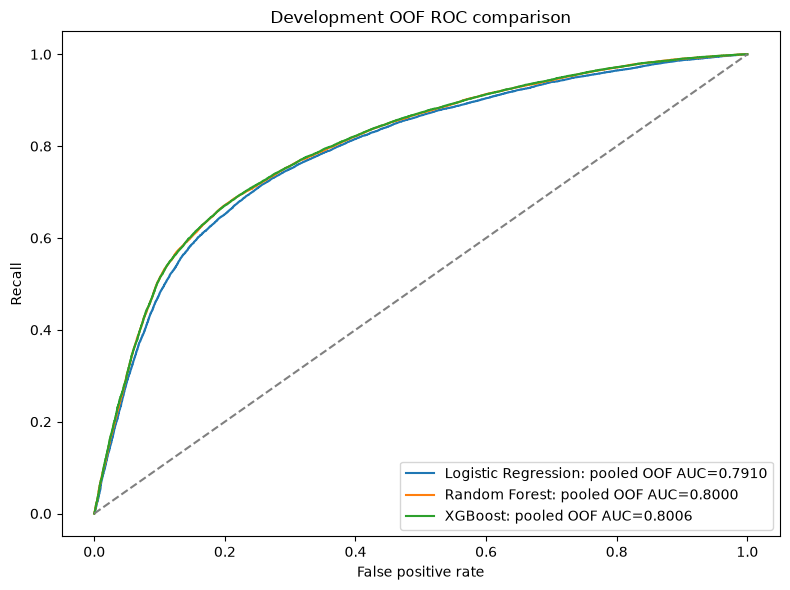

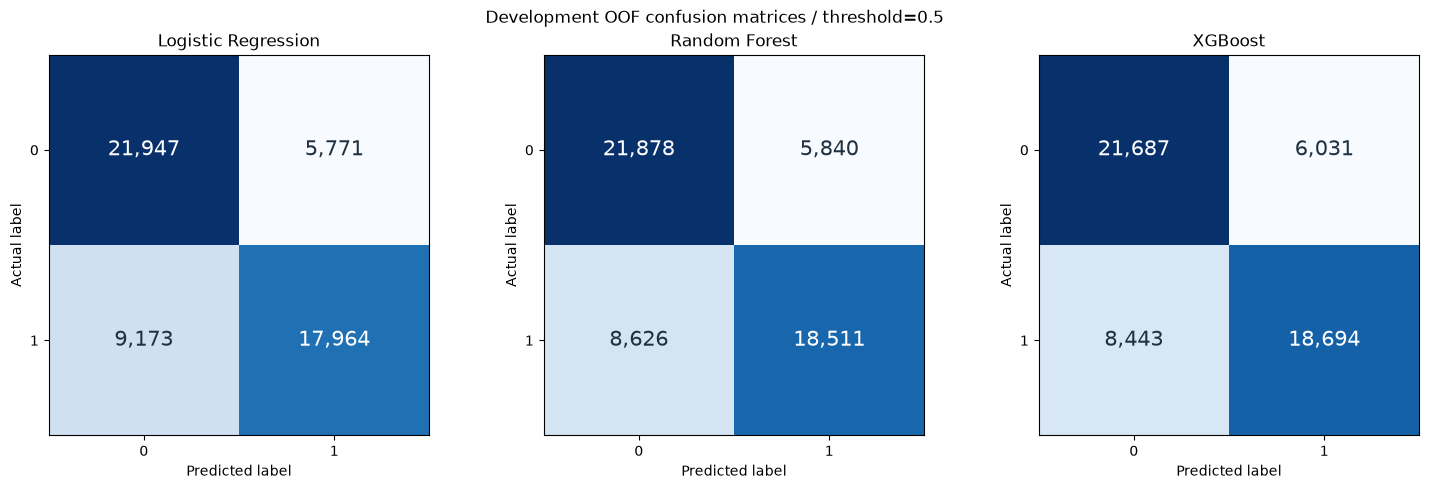

In [8]:
# Models trained on each validation record's own training fold generated these scores.
# The separately saved final model is fitted on all development records.
comparison_plots(results, ctx, STAGE_DIR)


In [9]:
history = compare_history(RUN_DIR, ["01_baseline", "02_round1", "03_round2"])
display(history[["stage", "model", "status", "training_accuracy", *METRICS]].round(6))

# Inspect, rather than automatically change, the development-stage candidate selection.
final_candidates = comparison.sort_values("roc_auc", ascending=False)
display(final_candidates[["model", *METRICS]].round(6))
print("Saved second-round output:", STAGE_DIR)
print("No final test evaluation or ranking is included in these three training notebooks.")


,stage,model,status,training_accuracy,roc_auc,accuracy,precision,recall,f1,specificity,average_precision
0,01_baseline,logistic_regression,trained,0.727618,0.791057,0.727591,0.756888,0.662048,0.706278,0.791760,0.769794
1,01_baseline,random_forest,trained,0.999713,0.763978,0.704822,0.705061,0.693408,0.699177,0.715997,0.746882
2,01_baseline,xgboost,trained,0.739281,0.800539,0.735849,0.754020,0.691712,0.721519,0.779061,0.781640
3,02_round1,logistic_regression,trained,0.727632,0.791059,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796
4,02_round1,random_forest,trained,0.743478,0.800122,0.736432,0.760839,0.681468,0.718956,0.790245,0.781407
5,02_round1,xgboost,trained,0.739295,0.800579,0.735794,0.753483,0.692523,0.721713,0.778159,0.781710
6,03_round2,logistic_regression,carried forward,0.727632,0.791059,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796
7,03_round2,random_forest,trained,0.742972,0.800125,0.736287,0.760190,0.682131,0.719041,0.789307,0.781467
8,03_round2,xgboost,trained,0.739440,0.800734,0.736141,0.756089,0.688875,0.720907,0.782416,0.782078


,model,roc_auc,accuracy,precision,recall,f1,specificity,average_precision
2,xgboost,0.800734,0.736141,0.756089,0.688875,0.720907,0.782416,0.782078
1,random_forest,0.800125,0.736287,0.760190,0.682131,0.719041,0.789307,0.781467
0,logistic_regression,0.791059,0.727573,0.756898,0.661974,0.706241,0.791796,0.769796


Saved second-round output: /Users/liujueshan/Desktop/comp4145/final project/notebooks/model_training_jupyter/runs/seven_features_run_01/03_round2
No final test evaluation or ranking is included in these three training notebooks.
